# **Aplicação dos ataques adversariais**
Esse notebook instancia novamente e aplica ataques adversariais contra os modelos treinados e otimizados nos outros notebooks.  

---

### *O que são?*
Os ataques adversariais são ataques direcionados com intuito de reduzir acurácia e precisão das arquiteturas de Deep Learning utilizando, em sua maioria, microruídos que bagunçam as redes neurais.

---

### *Quais são as arquiteturas?*
Foram utilizadas **Multilayer Perceptron (MLP)**, **Convolutional Neural Network (CNN)**, **Recurrent Neural Network (RNN)**, **Long Short-Term Memory (LSTM)**, e **Gated Recurrent Unit (GRU)**. Mais detalhes podem ser encontrados no README do projeto.

---

### *Quais são os ataques?*
Foram utilizados **Fast Gradient Sign Method (FGSM)**, **Projected Gradient Descent (PGD)** e **Ruído Gaussiano**. Mais detalhes podem ser encontrados no README do projeto.

---

In [2]:
# Importação das bibliotecas
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, train_test_split
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

# Definições globais (seed garante reprodutibilidade!!)
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EPSILONS = [0.0, 0.01, 0.05, 0.1, 0.2, 0.5, 0.8, 1.0]
PGD_ITERS = 5
PGD_ALPHA_FRACTION = 0.1
RUIDO_REPETICOES = 3
BATCH_SIZE = 256
MAX_TEST_SAMPLES = None
MODELOS = ["MLP", "RNN", "CNN", "GRU", "LSTM"]

DIRETORIO_EXECUCAO = Path.cwd().resolve()
CANDIDATOS_ROOT = (
    DIRETORIO_EXECUCAO,
    DIRETORIO_EXECUCAO / "deep-learning-redes",
    DIRETORIO_EXECUCAO.parent / "deep-learning-redes",
)
ROOT = next((caminho for caminho in CANDIDATOS_ROOT if (caminho / "Normal+Attacks.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError(f"Nao foi possivel localizar Normal+Attacks.csv a partir de {DIRETORIO_EXECUCAO}")
ROOT = ROOT.resolve()
DIR_PROJETO = ROOT.parent
ARQUIVO_DADOS = ROOT / "Normal+Attacks.csv"
DIR_MODELOS_ORIGINAIS = ROOT / "modelos_treinados"
DIR_RESULTADOS = DIR_PROJETO / "ataques-adversariais" / "resultados_adversariais"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
DIR_GRAFICOS = DIR_PROJETO / "graficos"
DIR_GRAFICOS.mkdir(parents=True, exist_ok=True)


def localizar_dados_tratados(diretorio, tipo):
    raiz = ROOT / diretorio
    caminho_resumo = raiz / "resumo_treinamento.json"
    pasta_modelos = raiz / "modelos"
    scaler = "scaler_binario.joblib" if tipo == "binario" else "scaler.joblib"
    arquivos_modelos = [pasta_modelos / f"{nome}_{tipo}.pt" for nome in MODELOS]
    if not caminho_resumo.exists() or not (pasta_modelos / scaler).exists() or not all(p.exists() for p in arquivos_modelos):
        raise FileNotFoundError(f"Resultados atuais de classificacao {tipo} nao encontrados ou incompletos em {raiz}")
    resumo = json.loads(caminho_resumo.read_text(encoding="utf-8"))
    if tipo == "multiclasse" and resumo.get("overlap_grupos_treino_teste") != 0:
        raise ValueError(f"A classificacao multiclasse nao confirma grupos disjuntos em {caminho_resumo}")
    return raiz


DIR_TRATADO_BINARIO = localizar_dados_tratados("classificacao_binaria_tratada", "binario")
DIR_TRATADO_MULTICLASSE = localizar_dados_tratados("classificacao_multiclasse_tratada", "multiclasse")
HP_BINARIO = json.loads((ROOT / "tuning_bayesiano" / "resumo_melhores_hp_binario.json").read_text(encoding="utf-8"))
HP_MULTICLASSE = json.loads((ROOT / "tuning_bayesiano" / "resumo_melhores_hp_multiclasse.json").read_text(encoding="utf-8"))

CASOS = {
    "binario_original": {
        "tipo": "binario", "dados_tratados": False,
        "model_dir": DIR_MODELOS_ORIGINAIS, "scaler_path": DIR_MODELOS_ORIGINAIS / "scaler_binario.joblib",
        "hp": HP_BINARIO,
    },
    "binario_tratado": {
        "tipo": "binario", "dados_tratados": True,
        "model_dir": DIR_TRATADO_BINARIO / "modelos", "scaler_path": DIR_TRATADO_BINARIO / "modelos" / "scaler_binario.joblib",
        "hp": HP_BINARIO,
    },
    "multiclasse_original": {
        "tipo": "multiclasse", "dados_tratados": False,
        "model_dir": DIR_MODELOS_ORIGINAIS, "scaler_path": DIR_MODELOS_ORIGINAIS / "scaler_multiclasse.joblib",
        "hp": HP_MULTICLASSE,
    },
    "multiclasse_tratado": {
        "tipo": "multiclasse", "dados_tratados": True,
        "model_dir": DIR_TRATADO_MULTICLASSE / "modelos", "scaler_path": DIR_TRATADO_MULTICLASSE / "modelos" / "scaler.joblib",
        "hp": HP_MULTICLASSE,
    },
}


def preparar_caso(chave, config):
    df = pd.read_csv(ARQUIVO_DADOS)
    scaler = joblib.load(config["scaler_path"])

    if not config["dados_tratados"]:
        X = df.drop(columns=["label"]).select_dtypes(include="number")
        if config["tipo"] == "binario":
            y = df["label"].astype(str).str.strip().str.lower().ne("normal").astype("int64").to_numpy()
            nomes_classes = ["Normal", "Ataque"]
        else:
            encoder = joblib.load(config["model_dir"] / "label_encoder_multiclasse.joblib")
            y = encoder.transform(df["label"])
            nomes_classes = encoder.classes_.tolist()
        X_treino, X_teste, y_treino, y_teste = train_test_split(
            X, y, test_size=0.25, random_state=SEED, stratify=y
        )
    else:
        df = df.copy()
        if config["tipo"] == "binario":
            df["target"] = df["label"].astype(str).str.strip().str.lower().ne("normal").astype("int64")
        else:
            df["label"] = df["label"].replace({"Reco": "Reco+Scanning", "Scanning": "Reco+Scanning"})
            df["target"] = df["label"]
        df = df.drop(columns=["fwd_seg_size_min"], errors="ignore")
        X_todas = df.drop(columns=["label", "target"], errors="ignore").select_dtypes(include="number")
        nomes_features = X_todas.columns.tolist()
        dados = X_todas.copy()
        dados["target"] = df["target"].to_numpy()
        dados = dados.drop_duplicates().reset_index(drop=True)
        X = dados[nomes_features]
        if config["tipo"] == "binario":
            y = dados["target"].to_numpy(dtype="int64")
            nomes_classes = ["Normal", "Ataque"]
            grupos = pd.util.hash_pandas_object(X, index=False).to_numpy()
            splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
        else:
            encoder = joblib.load(config["model_dir"] / "label_encoder.joblib")
            y = encoder.transform(dados["target"])
            nomes_classes = encoder.classes_.tolist()
            grupos = pd.util.hash_pandas_object(X, index=False).to_numpy()
            splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
        indices_treino, indices_teste = next(splitter.split(X, y, groups=grupos))
        X_treino, X_teste = X.iloc[indices_treino], X.iloc[indices_teste]
        y_treino, y_teste = y[indices_treino], y[indices_teste]

    nomes_features_scaler = list(scaler.feature_names_in_)
    X_teste = X_teste.loc[:, nomes_features_scaler]
    X_teste_np = scaler.transform(X_teste).astype(np.float32)
    y_teste_np = np.asarray(y_teste, dtype=np.int64)

    if MAX_TEST_SAMPLES is not None and len(y_teste_np) > MAX_TEST_SAMPLES:
        if MAX_TEST_SAMPLES < len(np.unique(y_teste_np)):
            raise ValueError("MAX_TEST_SAMPLES deve ser pelo menos o numero de classes do teste")
        _, indices = train_test_split(
            np.arange(len(y_teste_np)), train_size=MAX_TEST_SAMPLES,
            random_state=SEED, stratify=y_teste_np,
        )
        X_teste_np, y_teste_np = X_teste_np[indices], y_teste_np[indices]

    return X_teste_np, y_teste_np, nomes_classes, nomes_features_scaler


class MLPModelo(nn.Module):
    def __init__(self, n_features, hp, n_outputs):
        super().__init__()
        camadas = []
        anterior = n_features
        for indice in range(hp["n_camadas"]):
            unidades = hp[f"unidades_{indice}"]
            camadas.extend([nn.Linear(anterior, unidades), nn.ReLU() if hp["ativacao"] == "relu" else nn.Tanh()])
            dropout = hp[f"dropout_{indice}"]
            if dropout > 0:
                camadas.append(nn.Dropout(dropout))
            anterior = unidades
        camadas.append(nn.Linear(anterior, n_outputs))
        self.rede = nn.Sequential(*camadas)

    def forward(self, x):
        return self.rede(x)


class RecorrenteModelo(nn.Module):
    def __init__(self, tipo, hp, n_outputs):
        super().__init__()
        self.camadas = nn.ModuleList()
        self.dropouts = nn.ModuleList()
        anterior = 1
        tipos = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}
        for indice in range(hp["n_camadas"]):
            unidades = hp[f"unidades_{indice}"]
            self.camadas.append(tipos[tipo](anterior, unidades, batch_first=True))
            dropout = hp[f"dropout_{indice}"]
            self.dropouts.append(nn.Dropout(dropout) if dropout > 0 else nn.Identity())
            anterior = unidades
        self.densa = nn.Linear(anterior, 64)
        self.saida = nn.Linear(64, n_outputs)

    def forward(self, x):
        for indice, (camada, dropout) in enumerate(zip(self.camadas, self.dropouts)):
            saida, _ = camada(x)
            saida = dropout(saida)
            x = saida if indice < len(self.camadas) - 1 else saida[:, -1, :]
        return self.saida(torch.relu(self.densa(x)))


class CNNModelo(nn.Module):
    def __init__(self, hp, n_outputs):
        super().__init__()
        camadas = []
        anterior = 1
        kernel = hp["kernel_size"]
        for indice in range(hp["n_blocos_conv"]):
            filtros = hp[f"filtros_{indice}"]
            camadas.extend([nn.Conv1d(anterior, filtros, kernel, padding=kernel // 2), nn.ReLU(), nn.MaxPool1d(2, ceil_mode=True)])
            anterior = filtros
        self.conv = nn.Sequential(*camadas)
        self.pool_global = nn.AdaptiveAvgPool1d(1)
        self.densa = nn.Linear(anterior, 128)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(hp.get("dropout_final", 0.2))
        self.saida = nn.Linear(128, n_outputs)

    def forward(self, x):
        x = self.pool_global(self.conv(x)).squeeze(-1)
        return self.saida(self.dropout(self.relu(self.densa(x))))


def criar_modelo(nome, config, checkpoint):
    hp = config["hp"][nome]["hiperparametros"]
    binario = config["tipo"] == "binario"
    n_outputs = 1 if binario else int(checkpoint["n_classes"])
    n_features = int(checkpoint["n_features"])
    if nome == "MLP":
        modelo = MLPModelo(n_features, hp, n_outputs)
    elif nome == "CNN":
        modelo = CNNModelo(hp, n_outputs)
    else:
        modelo = RecorrenteModelo(nome, hp, n_outputs)
    modelo.load_state_dict(checkpoint["state_dict"])
    modelo.to(DEVICE).eval()
    return modelo


print(f"Dispositivo: {DEVICE}")
print(f"Dados binarios tratados: {DIR_TRATADO_BINARIO}")
print(f"Dados multiclasse tratados: {DIR_TRATADO_MULTICLASSE}")
print(f"Resultados atuais: {DIR_RESULTADOS}")

Dispositivo: cuda
Dados binarios tratados: /home/luish/VSCode/IC/DL/deep-learning-redes/classificacao_binaria_tratada
Dados multiclasse tratados: /home/luish/VSCode/IC/DL/deep-learning-redes/classificacao_multiclasse_tratada
Resultados atuais: /home/luish/VSCode/IC/DL/ataques-adversariais/resultados_adversariais


In [3]:
from contextlib import contextmanager


def preparar_entrada(x, nome):
    if nome in ("RNN", "GRU", "LSTM"):
        return x.unsqueeze(-1)
    if nome == "CNN":
        return x.unsqueeze(-1).permute(0, 2, 1)
    return x


def loss_modelo(logits, y, binario):
    if binario:
        return nn.functional.binary_cross_entropy_with_logits(logits.view(-1), y.float())
    return nn.functional.cross_entropy(logits, y.long())


def prever(modelo, nome, X_np, binario):
    previsoes = []
    probabilidades = []
    with torch.no_grad():
        for inicio in range(0, len(X_np), BATCH_SIZE):
            xb = torch.as_tensor(X_np[inicio:inicio + BATCH_SIZE], dtype=torch.float32, device=DEVICE)
            logits = modelo(preparar_entrada(xb, nome))
            if binario:
                probs = torch.sigmoid(logits.view(-1))
                probabilidades.extend(probs.cpu().numpy().tolist())
                previsoes.extend((probs >= 0.5).long().cpu().numpy().tolist())
            else:
                previsoes.extend(torch.argmax(logits, dim=1).cpu().numpy().tolist())
    return np.asarray(previsoes, dtype=np.int64), np.asarray(probabilidades, dtype=np.float32)


def medir(y_true, y_pred, class_names, binario):
    labels = np.arange(len(class_names))
    matriz = confusion_matrix(y_true, y_pred, labels=labels)
    metricas = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "classification_report": classification_report(
            y_true, y_pred, labels=labels, target_names=class_names,
            output_dict=True, zero_division=0,
        ),
        "confusion_matrix": matriz.tolist(),
    }
    if binario:
        tn, fp, fn, tp = matriz.ravel()
        metricas.update({
            "false_positive_rate": float(fp / (fp + tn)) if fp + tn else 0.0,
            "specificity": float(tn / (tn + fp)) if tn + fp else 0.0,
            "attack_recall": float(tp / (tp + fn)) if tp + fn else 0.0,
            "attack_precision": float(tp / (tp + fp)) if tp + fp else 0.0,
            "true_negative": int(tn), "false_positive": int(fp),
            "false_negative": int(fn), "true_positive": int(tp),
        })
    return metricas


@contextmanager
def modo_gradiente(modelo):
    # cuDNN exige RNNs em modo train para derivar gradientes; Dropout permanece desativado.
    modelo.train()
    for modulo in modelo.modules():
        if isinstance(modulo, nn.Dropout):
            modulo.eval()
    try:
        yield
    finally:
        modelo.eval()


def gerar_fgsm(modelo, nome, xb, yb, binario, epsilon):
    if epsilon == 0:
        return xb.detach()
    with modo_gradiente(modelo):
        x_grad = xb.detach().requires_grad_(True)
        logits = modelo(preparar_entrada(x_grad, nome))
        loss = loss_modelo(logits, yb, binario)
        gradiente = torch.autograd.grad(loss, x_grad)[0]
        return (x_grad + epsilon * gradiente.sign()).detach()


def gerar_pgd(modelo, nome, xb, yb, binario, epsilon):
    if epsilon == 0:
        return xb.detach()
    x_original = xb.detach()
    alpha = max(epsilon * PGD_ALPHA_FRACTION, 1e-6)
    x_adv = x_original + torch.empty_like(x_original).uniform_(-epsilon, epsilon)
    with modo_gradiente(modelo):
        for _ in range(PGD_ITERS):
            x_adv = x_adv.detach().requires_grad_(True)
            logits = modelo(preparar_entrada(x_adv, nome))
            loss = loss_modelo(logits, yb, binario)
            gradiente = torch.autograd.grad(loss, x_adv)[0]
            with torch.no_grad():
                x_adv = x_adv + alpha * gradiente.sign()
                x_adv = torch.maximum(torch.minimum(x_adv, x_original + epsilon), x_original - epsilon)
    return x_adv.detach()


def aplicar_ataque(modelo, nome, X_np, y_np, binario, epsilon, ataque, seed):
    torch.manual_seed(seed)
    resultados = []
    for inicio in range(0, len(X_np), BATCH_SIZE):
        xb = torch.as_tensor(X_np[inicio:inicio + BATCH_SIZE], dtype=torch.float32, device=DEVICE)
        yb = torch.as_tensor(y_np[inicio:inicio + BATCH_SIZE], dtype=torch.long, device=DEVICE)
        if ataque == "fgsm":
            x_adv = gerar_fgsm(modelo, nome, xb, yb, binario, epsilon)
        elif ataque == "pgd":
            x_adv = gerar_pgd(modelo, nome, xb, yb, binario, epsilon)
        else:
            x_adv = xb + epsilon * torch.randn_like(xb)
        resultados.append(x_adv.detach().cpu().numpy())
    return np.concatenate(resultados, axis=0)


def carregar_checkpoint(caso, nome):
    sufixo = "binario" if caso["tipo"] == "binario" else "multiclasse"
    caminho = caso["model_dir"] / f"{nome}_{sufixo}.pt"
    checkpoint = torch.load(caminho, map_location=DEVICE, weights_only=False)
    scaler = joblib.load(caso["scaler_path"])
    if int(checkpoint["n_features"]) != int(scaler.n_features_in_):
        raise ValueError(f"Features do checkpoint e scaler nao coincidem: {caminho}")
    modelo = criar_modelo(nome, caso, checkpoint)
    return modelo, checkpoint


def avaliar_modelo(caso_nome, caso, nome, X_np, y_np, class_names, epsilons=EPSILONS):
    modelo, checkpoint = carregar_checkpoint(caso, nome)
    binario = caso["tipo"] == "binario"
    y_pred_limpo, _ = prever(modelo, nome, X_np, binario)
    resultados = []
    metricas_limpas = medir(y_np, y_pred_limpo, class_names, binario)

    for epsilon_indice, epsilon in enumerate(epsilons):
        for ataque_indice, ataque in enumerate(("fgsm", "pgd", "ruido_gaussiano")):
            repeticoes = RUIDO_REPETICOES if ataque == "ruido_gaussiano" and epsilon > 0 else 1
            metricas_repetidas = []
            for repeticao in range(repeticoes):
                seed_ataque = SEED + epsilon_indice * 1000 + ataque_indice * 100 + repeticao
                X_adv = aplicar_ataque(
                    modelo, nome, X_np, y_np, binario, epsilon, ataque, seed_ataque
                )
                y_pred, _ = prever(modelo, nome, X_adv, binario)
                metricas_repetidas.append(medir(y_np, y_pred, class_names, binario))

            linha = {
                "caso": caso_nome,
                "modelo": nome,
                "tipo": caso["tipo"],
                "ataque": ataque,
                "epsilon": float(epsilon),
                "amostras": int(len(y_np)),
                "accuracy_limpa": metricas_limpas["accuracy"],
                "macro_f1_limpo": metricas_limpas["macro_f1"],
            }
            for chave in ("accuracy", "macro_f1", "false_positive_rate", "specificity", "attack_recall", "attack_precision"):
                valores = [m[chave] for m in metricas_repetidas if chave in m]
                if valores:
                    linha[chave] = float(np.mean(valores))
                    if len(valores) > 1:
                        linha[f"{chave}_std"] = float(np.std(valores))
            resultados.append(linha)

    del modelo
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return resultados, metricas_limpas


print("Funcoes de inferencia, ataques e metricas prontas.")

Funcoes de inferencia, ataques e metricas prontas.


## **Métricas**

In [4]:
DADOS_CASOS = {}
METRICAS_LIMPAS = {}

for caso_nome, caso in CASOS.items():
    X_teste, y_teste, nomes_classes, nomes_features = preparar_caso(caso_nome, caso)
    DADOS_CASOS[caso_nome] = {
        "X": X_teste,
        "y": y_teste,
        "class_names": nomes_classes,
        "feature_names": nomes_features,
    }
    METRICAS_LIMPAS[caso_nome] = {}
    print(f"\n{caso_nome}: {len(y_teste):,} exemplos, {len(nomes_features)} features")
    print("Classes no teste:", dict(zip(*np.unique(y_teste, return_counts=True))))

    for nome in MODELOS:
        modelo, checkpoint = carregar_checkpoint(caso, nome)
        y_pred, _ = prever(modelo, nome, X_teste, caso["tipo"] == "binario")
        metricas = medir(y_teste, y_pred, nomes_classes, caso["tipo"] == "binario")
        METRICAS_LIMPAS[caso_nome][nome] = metricas
        print(
            f"  {nome:5s} | acuracia={metricas['accuracy']:.4f} "
            f"| F1 macro={metricas['macro_f1']:.4f}"
        )
        del modelo

print("\nValidacao limpa concluida. Nenhum ataque foi executado nesta celula.")


binario_original: 37,359 exemplos, 44 features
Classes no teste: {np.int64(0): np.int64(3361), np.int64(1): np.int64(33998)}
  MLP   | acuracia=0.9263 | F1 macro=0.6552
  RNN   | acuracia=0.9247 | F1 macro=0.6478
  CNN   | acuracia=0.9269 | F1 macro=0.6556
  GRU   | acuracia=0.9265 | F1 macro=0.6546
  LSTM  | acuracia=0.9263 | F1 macro=0.6582

binario_tratado: 8,911 exemplos, 43 features
Classes no teste: {np.int64(0): np.int64(134), np.int64(1): np.int64(8777)}
  MLP   | acuracia=0.9843 | F1 macro=0.8088
  RNN   | acuracia=0.9856 | F1 macro=0.5861
  CNN   | acuracia=0.9863 | F1 macro=0.7672
  GRU   | acuracia=0.9856 | F1 macro=0.5392
  LSTM  | acuracia=0.9856 | F1 macro=0.5392

multiclasse_original: 37,359 exemplos, 44 features
Classes no teste: {np.int64(0): np.int64(1276), np.int64(1): np.int64(3573), np.int64(2): np.int64(3530), np.int64(3): np.int64(12), np.int64(4): np.int64(50), np.int64(5): np.int64(291), np.int64(6): np.int64(3361), np.int64(7): np.int64(12534), np.int64(8): 

In [5]:
# Verificacao rapida de gradientes e formatos; usa poucos exemplos e nao grava resultados de avaliacao.
N_AMOSTRAS_SMOKE = 8
EPSILON_SMOKE = 0.01

for caso_nome, caso in CASOS.items():
    dados = DADOS_CASOS[caso_nome]
    X_smoke = dados["X"][:N_AMOSTRAS_SMOKE]
    y_smoke = dados["y"][:N_AMOSTRAS_SMOKE]
    for nome in MODELOS:
        modelo, _ = carregar_checkpoint(caso, nome)
        binario = caso["tipo"] == "binario"
        adversariais = {}
        for ataque in ("fgsm", "pgd", "ruido_gaussiano"):
            adversariais[ataque] = aplicar_ataque(
                modelo, nome, X_smoke, y_smoke, binario,
                EPSILON_SMOKE, ataque, SEED,
            )
            assert adversariais[ataque].shape == X_smoke.shape
            assert np.isfinite(adversariais[ataque]).all()
        del modelo
    print(f"{caso_nome}: as 5 arquiteturas passaram FGSM, PGD e ruido.")

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
print("Verificacao rapida concluida; a celula final ainda executa a avaliacao completa.")

binario_original: as 5 arquiteturas passaram FGSM, PGD e ruido.
binario_tratado: as 5 arquiteturas passaram FGSM, PGD e ruido.
multiclasse_original: as 5 arquiteturas passaram FGSM, PGD e ruido.
multiclasse_tratado: as 5 arquiteturas passaram FGSM, PGD e ruido.
Verificacao rapida concluida; a celula final ainda executa a avaliacao completa.


## **Geração dos resultados e gráficos**


Executando ataques: binario_original


binario_original:   0%|          | 0/5 [00:00<?, ?it/s]


Executando ataques: binario_tratado


binario_tratado:   0%|          | 0/5 [00:00<?, ?it/s]


Executando ataques: multiclasse_original


multiclasse_original:   0%|          | 0/5 [00:00<?, ?it/s]


Executando ataques: multiclasse_tratado


multiclasse_tratado:   0%|          | 0/5 [00:00<?, ?it/s]

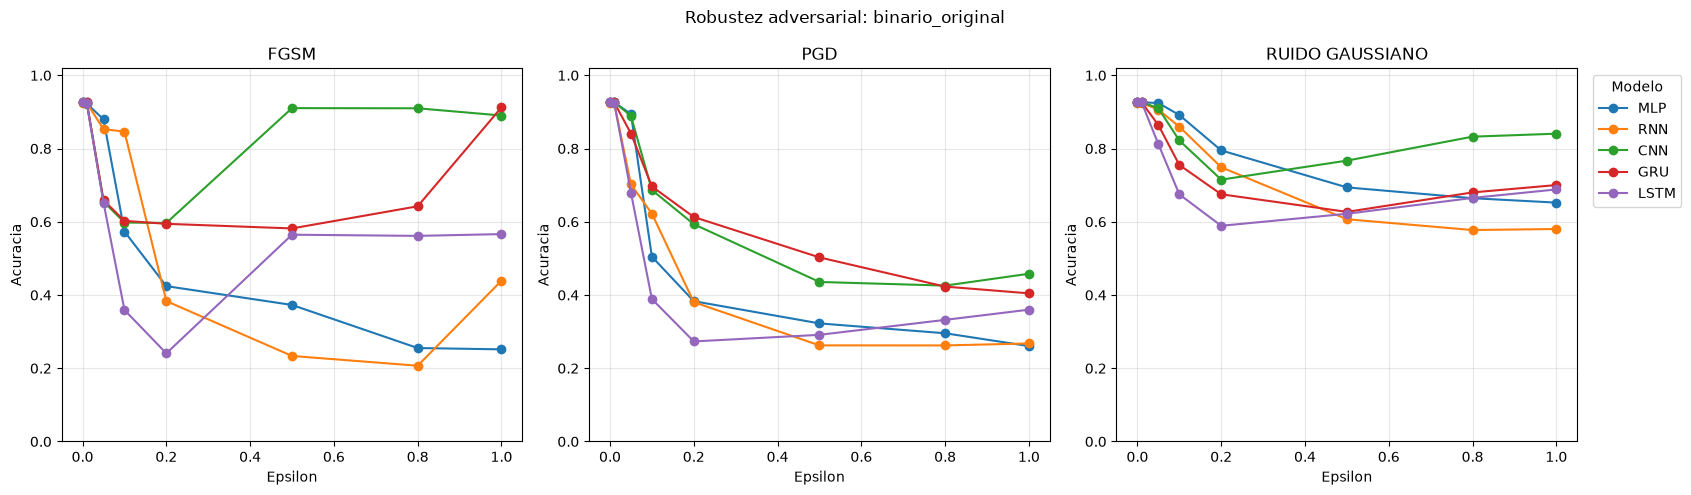

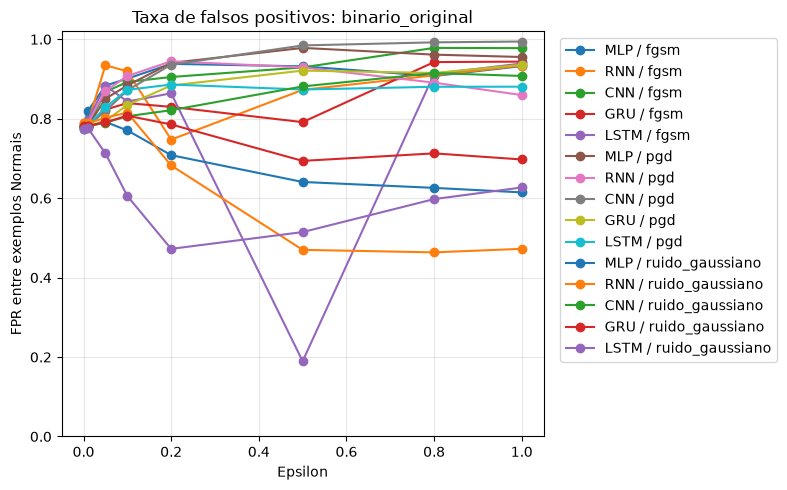

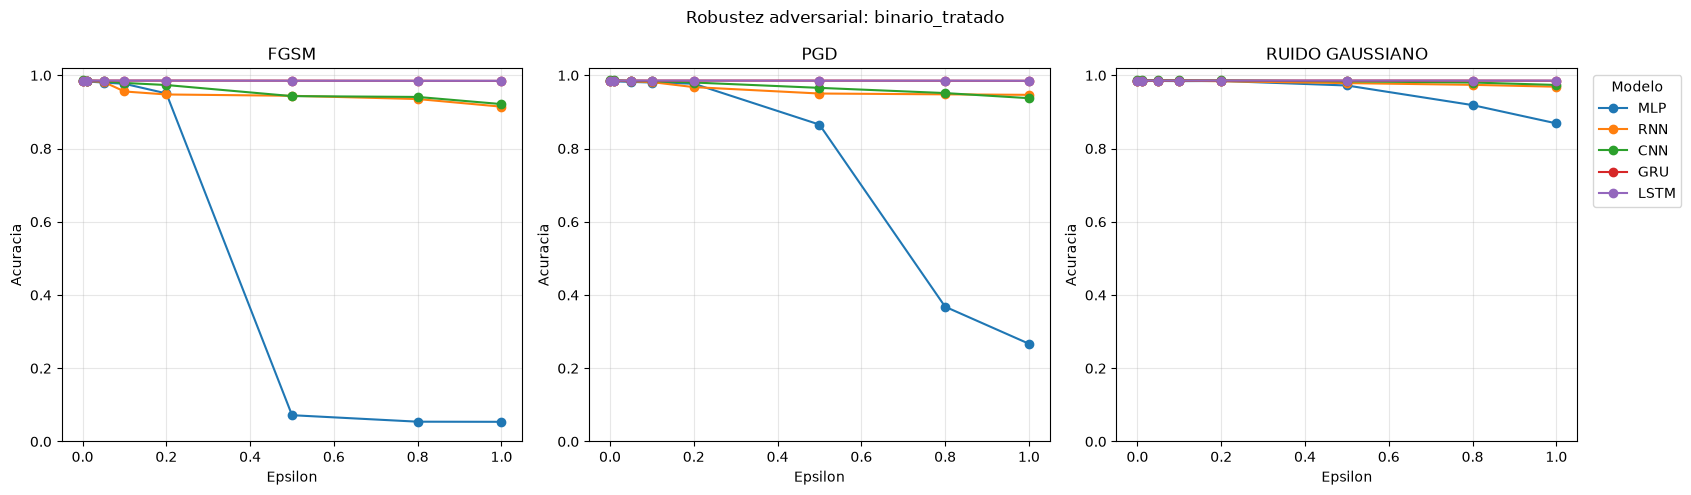

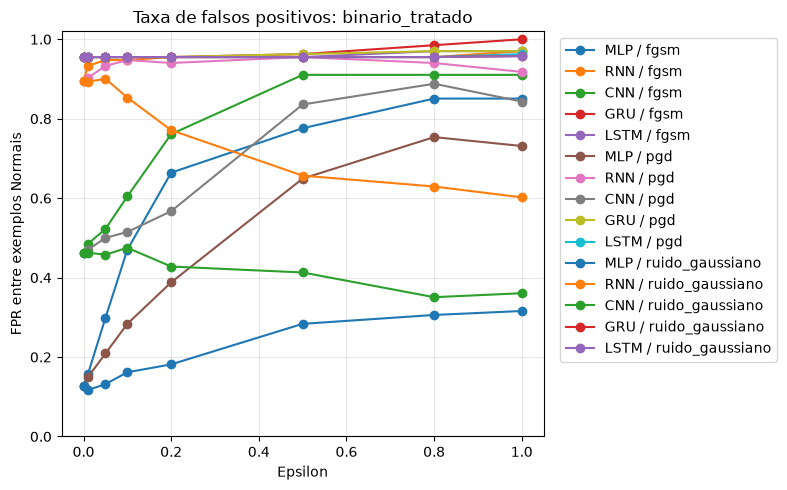

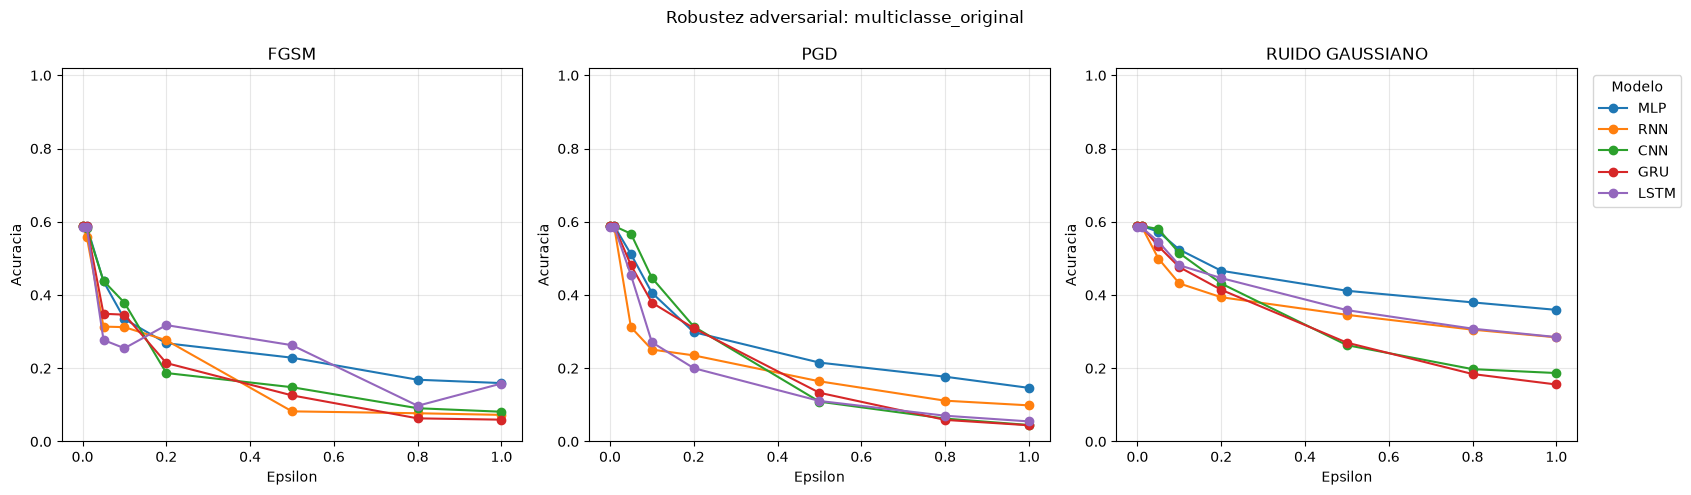

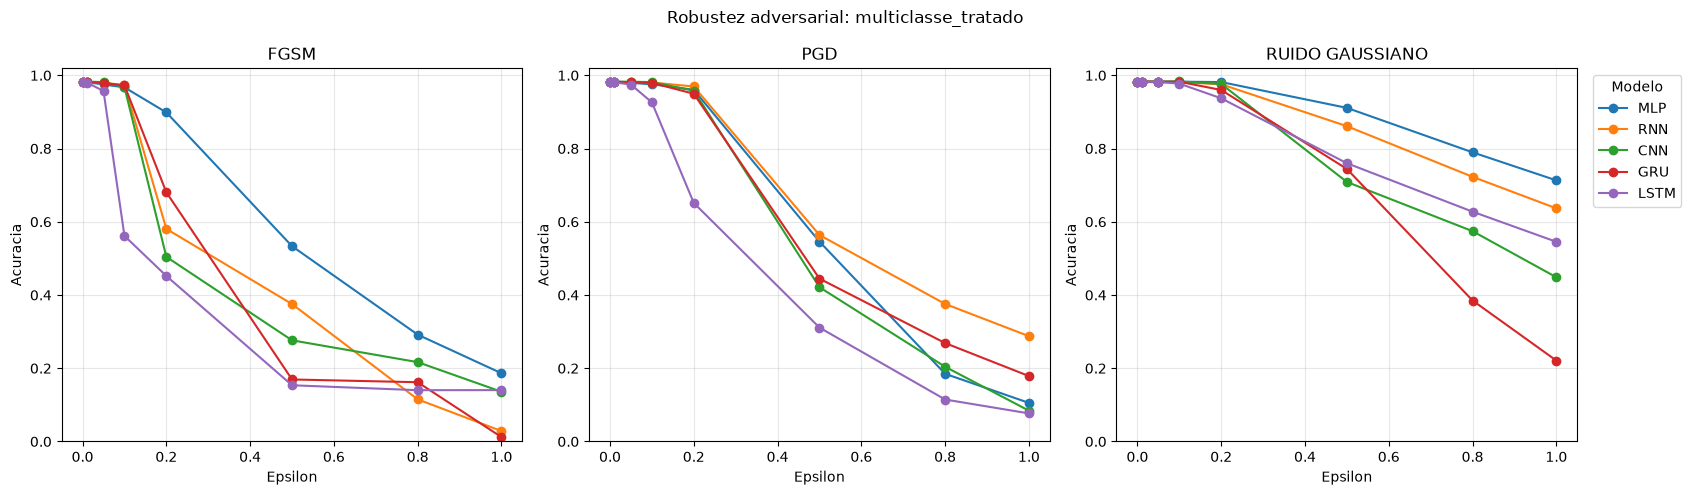


Metricas CSV: resultados_adversariais/metricas_ataques.csv
Metricas JSON: resultados_adversariais/metricas_ataques.json
Graficos e arquivos desta execucao: resultados_adversariais


In [6]:
RESULTADOS = []
for caso_indice, (caso_nome, caso) in enumerate(CASOS.items()):
    dados = DADOS_CASOS[caso_nome]
    print(f"\nExecutando ataques: {caso_nome}")
    for modelo_indice, nome in enumerate(tqdm(MODELOS, desc=caso_nome)):
        linhas, _ = avaliar_modelo(
            caso_nome,
            caso,
            nome,
            dados["X"],
            dados["y"],
            dados["class_names"],
        )
        for linha in linhas:
            linha["origem_modelos"] = (
                "classificacao_binaria_tratada" if caso_nome == "binario_tratado"
                else "classificacao_multiclasse_tratada" if caso_nome == "multiclasse_tratado"
                else "original"
            )
        RESULTADOS.extend(linhas)

resultados_df = pd.DataFrame(RESULTADOS)
csv_path = DIR_RESULTADOS / "metricas_ataques.csv"
resultados_df.to_csv(csv_path, index=False)

relatorio_json = {
    "configuracao": {
        "seed": SEED,
        "epsilons": EPSILONS,
        "pgd_iterations": PGD_ITERS,
        "pgd_alpha_fraction": PGD_ALPHA_FRACTION,
        "gaussian_repeats": RUIDO_REPETICOES,
        "batch_size": BATCH_SIZE,
        "max_test_samples": MAX_TEST_SAMPLES,
        "feature_space": "StandardScaler; epsilon/sigma em unidades do espaco padronizado",
        "binary_threshold": 0.5,
        "dados_binarios_tratados": "classificacao_binaria_tratada",
        "dados_multiclasse_tratados": "classificacao_multiclasse_tratada",
    },
    "metricas_limpas": METRICAS_LIMPAS,
    "resultados_ataques": RESULTADOS,
}
json_path = DIR_RESULTADOS / "metricas_ataques.json"
json_path.write_text(json.dumps(relatorio_json, indent=2, ensure_ascii=False), encoding="utf-8")

for caso_nome, caso in CASOS.items():
    dados_caso = resultados_df[resultados_df["caso"] == caso_nome]
    fig, eixos = plt.subplots(1, 3, figsize=(17, 5), sharex=True)
    for eixo, ataque in zip(eixos, ("fgsm", "pgd", "ruido_gaussiano")):
        subconjunto = dados_caso[dados_caso["ataque"] == ataque]
        for nome in MODELOS:
            serie = subconjunto[subconjunto["modelo"] == nome].sort_values("epsilon")
            eixo.plot(serie["epsilon"], serie["accuracy"], marker="o", label=nome)
        eixo.set_title(ataque.replace("_", " ").upper())
        eixo.set_xlabel("Epsilon")
        eixo.set_ylabel("Acuracia")
        eixo.set_ylim(0, 1.02)
        eixo.grid(alpha=0.3)
    eixos[-1].legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle(f"Robustez adversarial: {caso_nome}")
    fig.tight_layout()
    fig.savefig(DIR_GRAFICOS / f"robustez_{caso_nome.replace('_tratado', '_tratada')}_curvas.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    if caso["tipo"] == "binario":
        fig, eixo = plt.subplots(figsize=(8, 5))
        subconjunto = dados_caso[dados_caso["ataque"].isin(["fgsm", "pgd", "ruido_gaussiano"])]
        for ataque in ("fgsm", "pgd", "ruido_gaussiano"):
            por_ataque = subconjunto[subconjunto["ataque"] == ataque]
            for nome in MODELOS:
                serie = por_ataque[por_ataque["modelo"] == nome].sort_values("epsilon")
                eixo.plot(serie["epsilon"], serie["false_positive_rate"], marker="o", label=f"{nome} / {ataque}")
        eixo.set_title(f"Taxa de falsos positivos: {caso_nome}")
        eixo.set_xlabel("Epsilon")
        eixo.set_ylabel("FPR entre exemplos Normais")
        eixo.set_ylim(0, 1.02)
        eixo.grid(alpha=0.3)
        eixo.legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=1)
        fig.tight_layout()
        fig.savefig(DIR_GRAFICOS / f"robustez_{caso_nome.replace('_tratado', '_tratada')}_falsos_positivos.png", dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(fig)

DIR_RESULTADOS_RELATIVO = Path("resultados_adversariais")
print(f"\nMetricas CSV: {DIR_RESULTADOS_RELATIVO / csv_path.name}")
print(f"Metricas JSON: {DIR_RESULTADOS_RELATIVO / json_path.name}")
print(f"Graficos e arquivos desta execucao: {DIR_RESULTADOS_RELATIVO}")